# 01. Exploratory Data Analysis
Goal: understand the California housing dataset before modelling.
Target: `MedHouseVal`, median house value in units of $100,000.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/california_housing.csv")
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Structure and missing values

In [2]:
print(df.shape)
df.info()
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

(20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
Missing values: 0
Duplicate rows: 0


## Summary statistics

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


## Target distribution

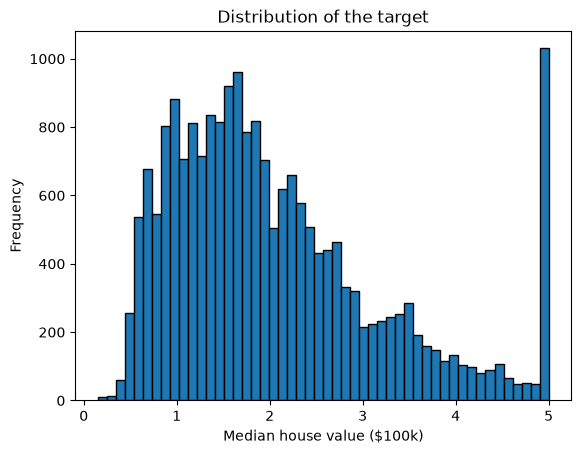

Values capped at 5.0: 992


In [4]:
df["MedHouseVal"].plot.hist(bins=50, edgecolor="black")
plt.xlabel("Median house value ($100k)")
plt.title("Distribution of the target")
plt.show()
print("Values capped at 5.0:", (df["MedHouseVal"] >= 5.0).sum())

## Feature distributions

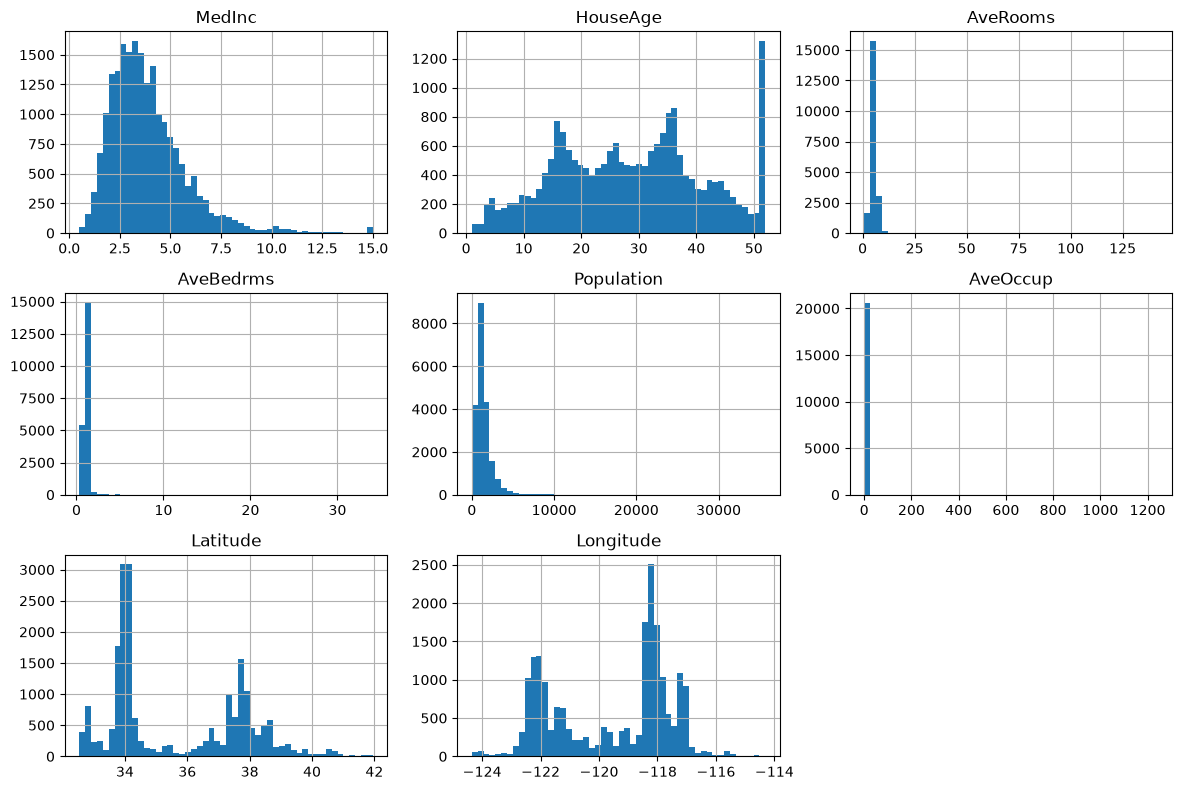

In [5]:
df.drop(columns="MedHouseVal").hist(bins=50, figsize=(12, 8))
plt.tight_layout()
plt.show()

## Correlation with the target

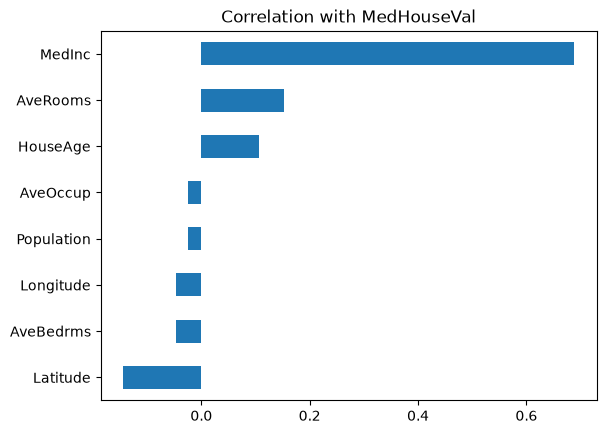

In [6]:
corr = df.corr()["MedHouseVal"].drop("MedHouseVal").sort_values()
corr.plot.barh()
plt.title("Correlation with MedHouseVal")
plt.show()

## Geography

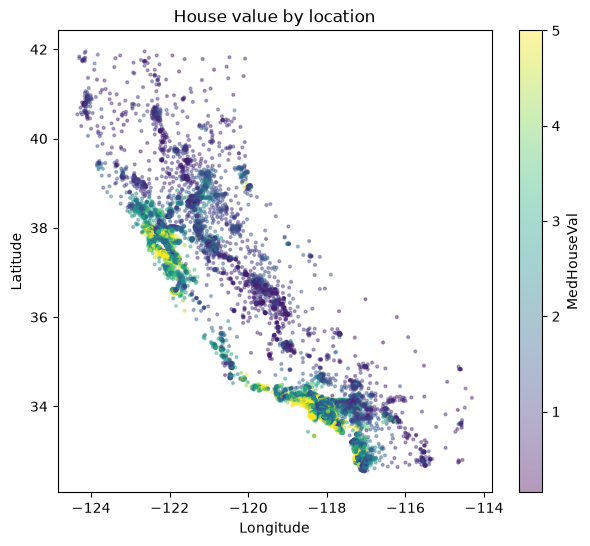

In [7]:
df.plot.scatter(x="Longitude", y="Latitude", c="MedHouseVal", cmap="viridis",
                s=4, alpha=0.4, figsize=(7, 6))
plt.title("House value by location")
plt.show()